# GLiNER multi-v2.1: zero-shot named-entity recognition (CPU inference)

Finds **spans of text** (names, places, dates, amounts, IDs…) for **entity types you choose at run time**, with no training.
Tests:
1. custom examples, in English and Tagalog
2. how the threshold changes results
3. English news with gold labels (CoNLL-2003, 60 sentences)
4. **Tagalog** Wikipedia with gold labels (WikiANN-tl, 60 sentences)
5. **invoice/receipt field extraction** from the OCR notebook's output, checked against the answer key

| | |
|---|---|
| Model | `urchade/gliner_multi-v2.1` (~289M parameters incl. a large multilingual vocabulary; Apache-2.0) |
| Runs on CPU? | **Yes.** ~1.5–3 GB of RAM, ~0.1–0.6 s per sentence, ~2 s for a full invoice page. All labels are scored in **one pass**, so adding labels costs little. |
| Languages | **Multilingual** (mDeBERTa-v3 backbone): English, Tagalog, Indonesian, Spanish, … |
| Max length | 384 words per pass. Longer texts are split into chunks (helper below). |

> **What it does:** GLiNER ("Generalist and Lightweight NER") reads the text and your label names **together** in one transformer pass.
> It builds a vector for every candidate **span** (1–12 words) and for every **label**, and scores how well each span matches each label.
> Spans scoring above the `threshold` are returned. Because labels are just text, you can ask for anything:
> `"person"`, `"medicine name"`, `"invoice number"`, `"Philippine province"`.
>
> | | |
> |---|---|
> | **Input** | text + a list of entity-type names (+ `threshold`, default 0.5) |
> | **Output** | a list of spans: `{"text": "Juan Dela Cruz", "label": "person", "start": 0, "end": 14, "score": 0.99}`, where `start`/`end` are character positions |
> | **Needs from you** | good label names (descriptive works best) and a threshold. Lower it to catch more, raise it to be more precise. |
>
> **vs BART-MNLI (other notebook):** BART labels the **whole text** ("this is about billing"). GLiNER labels **pieces inside** the text
> ("₱5,000 → amount"). They pair well: BART decides the document type, GLiNER extracts its fields.

In [1]:
import html, json, re, time, warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import HTML, display
from gliner import GLiNER

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)
DATA = Path("data"); OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)

/home/tsubame/miniconda3/envs/gliner/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | torch 2.15.0+cpu


/home/tsubame/miniconda3/envs/gliner/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Settings and model

In [2]:
MODEL_ID = "urchade/gliner_multi-v2.1"
THRESHOLD = 0.5

t = time.time()
model = GLiNER.from_pretrained(MODEL_ID).to(DEVICE).eval()
print(f"{MODEL_ID}: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M params, loaded in {time.time() - t:.1f}s")

PALETTE = ["#fde68a", "#bfdbfe", "#bbf7d0", "#fecaca", "#ddd6fe", "#fed7aa", "#a5f3fc", "#f5d0fe", "#d9f99d", "#e5e7eb"]

def highlight(text, ents, labels):
    # render entities as coloured, labelled spans
    colors = {l: PALETTE[i % len(PALETTE)] for i, l in enumerate(labels)}
    out, pos = [], 0
    for e in sorted(ents, key=lambda e: e["start"]):
        out.append(html.escape(text[pos:e["start"]]))
        out.append(f'<span style="background:{colors[e["label"]]};padding:1px 3px;border-radius:4px;color:#111">'
                   f'{html.escape(e["text"])} <sub style="font-size:70%">{e["label"]} {e["score"]:.2f}</sub></span>')
        pos = e["end"]
    out.append(html.escape(text[pos:]))
    return HTML('<div style="line-height:2;font-family:sans-serif">' + "".join(out).replace("\n", "<br>") + "</div>")

def extract(text, labels, threshold=THRESHOLD, max_chars=1500):
    # split long text on line breaks into chunks under the model's 384-word limit, keeping character offsets
    ents, start = [], 0
    chunks, buf, buf_start = [], "", 0
    for line in text.splitlines(keepends=True):
        if len(buf) + len(line) > max_chars and buf:
            chunks.append((buf_start, buf)); buf_start += len(buf); buf = ""
        buf += line
    if buf: chunks.append((buf_start, buf))
    for offset, chunk in chunks:
        for e in model.predict_entities(chunk, labels, threshold=threshold):
            ents.append({**e, "start": e["start"] + offset, "end": e["end"] + offset})
    return ents

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 1396.89it/s]

urchade/gliner_multi-v2.1: 289M params, loaded in 6.6s


## 1. Custom examples: any labels, any language

In [3]:
EXAMPLES = [
    ("Juan Dela Cruz paid ₱5,000 to BDO Unibank in Makati on March 3, 2025 for invoice INV-2291.",
     ["person", "amount", "bank", "city", "date", "invoice number"]),
    ("Si Manuel Quezon ay naging pangulo ng Pilipinas at ipinanganak sa Baler, Aurora noong 1878.",
     ["person", "country", "location", "date"]),
    ("Patient was prescribed 500 mg amoxicillin three times daily for a sinus infection by Dr. Reyes at St. Luke's Medical Center.",
     ["medicine", "dosage", "frequency", "disease", "doctor", "hospital"]),
    ("Apple unveiled the iPhone 17 in Cupertino; Tim Cook said shipments start September 19 at $799.",
     ["company", "product", "city", "person", "date", "price"]),
]
for text, labels in EXAMPLES:
    t = time.time()
    ents = model.predict_entities(text, labels, threshold=THRESHOLD)
    print(f"labels: {labels}  ({time.time() - t:.2f}s)")
    display(highlight(text, ents, labels))

labels: ['person', 'amount', 'bank', 'city', 'date', 'invoice number']  (0.23s)


labels: ['person', 'country', 'location', 'date']  (0.14s)


labels: ['medicine', 'dosage', 'frequency', 'disease', 'doctor', 'hospital']  (0.19s)


labels: ['company', 'product', 'city', 'person', 'date', 'price']  (0.15s)


The raw output for the first example:

In [4]:
display(pd.DataFrame(model.predict_entities(*EXAMPLES[0], threshold=THRESHOLD)).round(3))

,start,end,text,label,score
0,0,14,Juan Dela Cruz,person,0.988
1,20,26,"₱5,000",amount,0.883
2,30,41,BDO Unibank,bank,0.988
3,45,51,Makati,city,0.976
4,55,68,"March 3, 2025",date,0.982
5,81,89,INV-2291,invoice number,0.683


## 2. The threshold trades recall for precision

A lower threshold returns more spans (catches more, but with more false hits). A higher one returns fewer, surer spans.

In [5]:
text = ("The Department of Health and the World Health Organization met in Quezon City on Monday. "
        "Secretary Teodoro Herbosa said the Philippines will receive 2 million doses from Pfizer next month.")
labels = ["organization", "government agency", "city", "country", "person", "job title", "date", "quantity", "company"]
for th in [0.3, 0.5, 0.7]:
    ents = model.predict_entities(text, labels, threshold=th)
    print(f"threshold {th}: {len(ents)} entities")
    display(highlight(text, ents, labels))

threshold 0.3: 9 entities


threshold 0.5: 9 entities


threshold 0.7: 8 entities


## 3–4. Accuracy against gold labels: English (CoNLL-2003) and Tagalog (WikiANN)

Each sentence has human-annotated **person / organization / location** spans (CoNLL's "MISC" type is ignored).
A prediction counts as correct only if the **exact span and type** match.

- **Precision:** of the spans GLiNER returned, the share that were right.
- **Recall:** of the true spans, the share GLiNER found.
- **F1:** the balance of the two.

In [6]:
TYPE = {"PER": "person", "ORG": "organization", "LOC": "location"}

def evaluate(path, threshold=THRESHOLD):
    rows = [json.loads(l) for l in open(path)]
    tp, fp, fn = Counter(), Counter(), Counter()
    examples, t = [], time.time()
    for r in rows:
        toks = r["tokens"]; text = " ".join(toks)
        starts, pos = [], 0
        for w in toks:
            starts.append(pos); pos += len(w) + 1
        ends = [s + len(w) for s, w in zip(starts, toks)]
        gold = {(s, e, TYPE[k]) for s, e, k in r["entities"] if k in TYPE}
        pred = set()
        for ent in model.predict_entities(text, list(TYPE.values()), threshold=threshold):
            if ent["start"] in starts and ent["end"] in ends:
                pred.add((starts.index(ent["start"]), ends.index(ent["end"]) + 1, ent["label"]))
            else:
                pred.add((-1, -1, ent["label"]))   # span not aligned to words: always counts as wrong
        for g in gold: (tp if g in pred else fn)[g[2]] += 1
        for p in pred - gold: fp[p[2]] += 1
        examples.append((text, gold, pred))
    secs = time.time() - t
    table = {}
    for k in list(TYPE.values()) + ["overall"]:
        T = sum(tp.values()) if k == "overall" else tp[k]
        P = sum(fp.values()) if k == "overall" else fp[k]
        N = sum(fn.values()) if k == "overall" else fn[k]
        prec = T / (T + P) if T + P else 0; rec = T / (T + N) if T + N else 0
        table[k] = {"precision": prec, "recall": rec, "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0, "gold spans": T + N}
    return pd.DataFrame(table).T, examples, secs

RESULTS = {}
for name, path in [("English (CoNLL-2003)", DATA / "conll2003_en_60.jsonl"), ("Tagalog (WikiANN)", DATA / "wikiann_tl_60.jsonl")]:
    table, examples, secs = evaluate(path)
    RESULTS[name] = (table, examples, secs)
    print(f"{name}: {secs:.1f}s for 60 sentences ({secs / 60:.2f}s each)")
    display(table.style.format({"precision": "{:.0%}", "recall": "{:.0%}", "f1": "{:.0%}", "gold spans": "{:.0f}"}))

English (CoNLL-2003): 10.1s for 60 sentences (0.17s each)


,precision,recall,f1,gold spans
person,79%,90%,84%,41
organization,39%,49%,43%,41
location,55%,76%,64%,38
overall,57%,72%,63%,120


Tagalog (WikiANN): 8.4s for 60 sentences (0.14s each)


,precision,recall,f1,gold spans
person,70%,67%,68%,21
organization,31%,19%,24%,26
location,18%,38%,24%,16
overall,36%,40%,38%,63


A few sentences side by side: **gold** (human) vs **GLiNER**:

In [7]:
def show_gold_vs_pred(name, n=3):
    _, examples, _ = RESULTS[name]
    for text, gold, pred in examples[:n]:
        toks = text.split(" ")
        fmt = lambda S: sorted((" ".join(toks[s:e]), k) for s, e, k in S if s >= 0)
        print("TEXT :", text)
        print("GOLD :", fmt(gold))
        print("MODEL:", fmt(pred), "\n")

show_gold_vs_pred("English (CoNLL-2003)")
show_gold_vs_pred("Tagalog (WikiANN)")

TEXT : Adding to the comments by " Mr Yen " , as Sakakibara is known for his prominence in the currency market , was BOJ governor Matsushita 's remark .
GOLD : [('BOJ', 'organization'), ('Matsushita', 'person'), ('Mr Yen', 'person'), ('Sakakibara', 'person')]
MODEL: [('BOJ', 'organization'), ('Matsushita', 'person'), ('Mr Yen', 'person'), ('Sakakibara', 'location')] 

TEXT : With 65 minutes gone Indonesia 's Widodo Putra , who scored a spectacular goal against Kuwait on Wednesday , was again on target , breaking through the Korean defence to beat the keeper with a low shot .
GOLD : [('Indonesia', 'location'), ('Kuwait', 'location'), ('Widodo Putra', 'person')]
MODEL: [('Indonesia', 'location'), ('Korean defence', 'organization'), ('Kuwait', 'location'), ('Widodo Putra', 'person')] 

TEXT : U.S. barge rates were lightly quoted Friday on the St. Louis Merchants Exchange call session .
GOLD : [('St. Louis', 'location'), ('U.S.', 'location')]
MODEL: [('St. Louis Merchants Exchange', 'organ

F1 vs threshold (English set). Pick the threshold that suits your use:

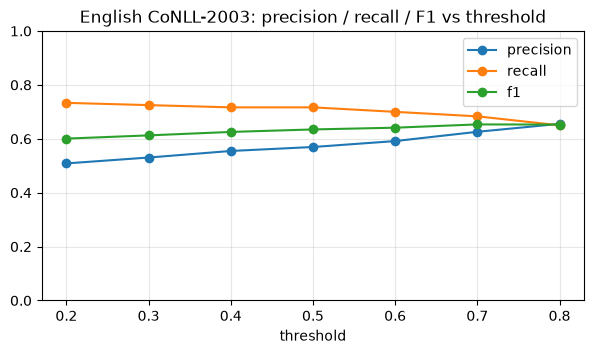

,precision,recall,f1
threshold,,,
0.200000,51%,73%,60%
0.300000,53%,72%,61%
0.400000,55%,72%,63%
0.500000,57%,72%,63%
0.600000,59%,70%,64%
0.700000,63%,68%,65%
0.800000,66%,65%,65%


In [8]:
sweep = []
for th in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    table, _, _ = evaluate(DATA / "conll2003_en_60.jsonl", threshold=th)
    sweep.append({"threshold": th, **table.loc["overall", ["precision", "recall", "f1"]].to_dict()})
SWEEP = pd.DataFrame(sweep).set_index("threshold")
ax = SWEEP.plot(marker="o", figsize=(7, 3.5), title="English CoNLL-2003: precision / recall / F1 vs threshold")
ax.set_ylim(0, 1); ax.grid(alpha=0.3); plt.show()
display(SWEEP.style.format("{:.0%}"))

## 5. Field extraction from invoices and receipts (OCR → GLiNER)

Uses the Markdown that SmolDocling produced in the OCR notebook (`../ocr_test/outputs/smoldocling/`). Run that notebook first.
Each answer-key value counts as found if a span with the right label matches it (spaces and `$` ignored).
The receipts are in **Indonesian**.

Two setups are compared:
- **short labels, threshold 0.5:** `"tax id"`, `"total amount"`, … GLiNER often returns the printed *field name* ("Tax Id") instead of the value.
- **descriptive labels, threshold 0.3, table pipes removed:** `"tax identification number"`, `"total amount of money"`, …

In [9]:
SRC = Path("../ocr_test/outputs/smoldocling")
DOCS_DIR = Path("../sample_docs")
SETUPS = {
    "short labels, th 0.5": (0.5, False, {
        "invoice_no": "invoice number", "invoice_date": "invoice date", "seller_tax_id": "tax id", "client_tax_id": "tax id",
        "iban": "iban", "total_gross_worth": "total amount", "total_price": "total amount", "subtotal_price": "subtotal",
        "cashprice": "cash paid", "changeprice": "change"}),
    "descriptive labels, th 0.3": (0.3, True, {
        "invoice_no": "invoice number", "invoice_date": "date", "seller_tax_id": "tax identification number",
        "client_tax_id": "tax identification number", "iban": "bank account number (IBAN)",
        "total_gross_worth": "total amount of money", "total_price": "total amount of money",
        "subtotal_price": "subtotal amount of money", "cashprice": "cash amount paid", "changeprice": "change amount returned"}),
}

KEY = {}
for kind, file in [("invoice", "invoice_rows.json"), ("receipt", "receipt_rows.json")]:
    for r in json.loads((DOCS_DIR / file).read_text())["rows"]:
        gt = json.loads(r["row"]["ground_truth"])["gt_parse"]
        flat = {**gt.get("header", {}), **gt.get("summary", {}), **gt.get("sub_total", {}), **gt.get("total", {})}
        KEY[f"{kind}_{r['row_idx'] + 1}"] = {f: flat[f].replace("$", "").strip() for f in SETUPS["short labels, th 0.5"][2] if f in flat}

norm = lambda s: re.sub(r"[\s$]", "", str(s)).lower()
strip_table = lambda t: re.sub(r"\|", " ", re.sub(r"^\|?[-| ]+\|?$", "", t, flags=re.M))   # Markdown table pipes -> spaces
files = sorted(SRC.glob("*.md"))
if not files:
    print("No SmolDocling outputs found. Run ../ocr_test/ocr_inference.ipynb first.")

CHECKS, EXTRACTED = {}, {}
for setup, (th, clean, fields) in SETUPS.items():
    labels = sorted(set(fields.values()))
    rows = []
    for f in files:
        name, text = f.stem, f.read_text()
        if clean: text = strip_table(text)
        t = time.time()
        ents = extract(text, labels, threshold=th)
        EXTRACTED[(setup, name)] = (text, ents, time.time() - t, labels)
        for field, value in KEY.get(name, {}).items():
            got = [e["text"] for e in ents if e["label"] == fields[field]]
            rows.append({"doc": name, "field": field, "label asked": fields[field], "expected": value,
                         "found": any(norm(value) == norm(g) or norm(value) in norm(g) for g in got),
                         "GLiNER returned": "; ".join(dict.fromkeys(got))[:80]})
    CHECKS[setup] = pd.DataFrame(rows)

if files:
    comp = pd.DataFrame({setup: {kind: f"{c[c.doc.str.startswith(kind)].found.sum()}/{(c.doc.str.startswith(kind)).sum()}"
                                 for kind in ["invoice", "receipt"]} for setup, c in CHECKS.items()})
    print("answer-key values extracted:"); display(comp)
    BEST = "descriptive labels, th 0.3"
    CHECK = CHECKS[BEST]
    CHECK.to_csv(OUT / "invoice_field_check.csv", index=False)
    print(f"details for '{BEST}':"); display(CHECK)
else:
    CHECK = pd.DataFrame()

answer-key values extracted:


,"short labels, th 0.5","descriptive labels, th 0.3"
invoice,10/30,19/30
receipt,3/15,3/15


details for 'descriptive labels, th 0.3':


,doc,field,label asked,expected,found,GLiNER returned
0,invoice_1,invoice_no,invoice number,97159829,True,97159829
1,invoice_1,invoice_date,date,09/18/2015,True,Date of issue; 09/18/2015
2,invoice_1,seller_tax_id,tax identification number,985-73-8194,True,985-73-8194; 994-72-1270
3,invoice_1,client_tax_id,tax identification number,994-72-1270,True,985-73-8194; 994-72-1270
4,invoice_1,iban,bank account number (IBAN),GB81LZWO32519172531418,True,IBAN; GB81LZWO32519172531418
5,invoice_1,total_gross_worth,total amount of money,"978,12",False,
6,invoice_2,invoice_no,invoice number,13194726,True,13194726
7,invoice_2,invoice_date,date,05/29/2021,True,Date of issue; 05/29/2021
8,invoice_2,seller_tax_id,tax identification number,952-73-7223,True,952-73-7223; 995-88-9495
9,invoice_2,client_tax_id,tax identification number,995-88-9495,True,952-73-7223; 995-88-9495


What GLiNER highlighted on one invoice and one receipt:

In [10]:
for name in ["invoice_1", "receipt_2"]:
    if ("descriptive labels, th 0.3", name) in EXTRACTED:
        text, ents, secs, labels = EXTRACTED[("descriptive labels, th 0.3", name)]
        print(f"{name} ({secs:.1f}s)")
        display(highlight(text, ents, labels))

invoice_1 (0.4s)


receipt_2 (0.2s)



**What this run showed (CPU):**
- **Fast:** ~0.15–0.2 s per sentence and under 1 s per invoice page, with all labels in one pass.
- **Custom labels just work:** all 6 entities in the payment example (person, amount, bank, city, date, invoice number),
  medical terms, products and prices, and **Tagalog** text ("Manuel Quezon → person, Pilipinas → country").
- **English news (CoNLL-2003): F1 63%** with exact-span matching. Person 84%, location 64%, organization 43%.
  Most errors are type confusions (a person or club tagged as a location) or span boundaries ("BOJ governor Matsushita" vs "Matsushita").
  Models trained on CoNLL score 90%+. Zero-shot trades accuracy for not needing training data.
- **Threshold:** on this set, raising it from 0.5 to 0.7–0.8 lifts F1 slightly (63% → 65%), trading recall for precision.
- **Tagalog Wikipedia (WikiANN): F1 38%.** Person names are fine (68%); organizations and locations are weak.
  WikiANN's labels are generated automatically from Wikipedia links, so some "gold" spans are themselves debatable.
- **Invoice fields: label wording matters a lot.** Short labels at threshold 0.5 found 10 of 30 values.
  **Descriptive labels at threshold 0.3 found 19 of 30.** With short labels, GLiNER often returned the printed field name ("Tax Id") instead of its value.
- **Receipts: 3 of 15** in both setups. The OCR'd receipt text is a jumble of Indonesian item names and amounts, and "total", "cash" and "change"
  look alike without the layout. Use it on clean text, or pair it with a layout-aware model.


## 6. Summary

In [11]:
rows = [{"test": name, "F1": t.loc["overall", "f1"], "precision": t.loc["overall", "precision"], "recall": t.loc["overall", "recall"],
         "s per text": secs / 60} for name, (t, _, secs) in RESULTS.items()]
if len(CHECK):
    for kind in ["invoice", "receipt"]:
        sub = CHECK[CHECK.doc.str.startswith(kind)]
        secs = [EXTRACTED[("descriptive labels, th 0.3", d)][2] for d in sub.doc.unique()]
        rows.append({"test": f"{kind} field extraction (found %)", "F1": sub.found.mean(), "s per text": sum(secs) / len(secs)})
SUMMARY = pd.DataFrame(rows)
SUMMARY.to_csv(OUT / "summary.csv", index=False)
display(SUMMARY.style.format({"F1": "{:.0%}", "precision": "{:.0%}", "recall": "{:.0%}", "s per text": "{:.2f}"}, na_rep="—"))

,test,F1,precision,recall,s per text
0,English (CoNLL-2003),63%,57%,72%,0.17
1,Tagalog (WikiANN),38%,36%,40%,0.14
2,invoice field extraction (found %),63%,—,—,0.75
3,receipt field extraction (found %),20%,—,—,0.24
